Caso: rampa | beta (soma seis grupos): 0.00708000 | Lambda: 2.37884e-05
n_alg(0+): 0.54164374 | n_corr(0+): 1
Erro abs. maximo em n: 0.00013415
Erro abs. maximo da norma-1 do estado: 0.000214499
Envelope integrado no final: 0.000695403
Relação max ||erro||_1 / E (excluindo t=0): 1.08876


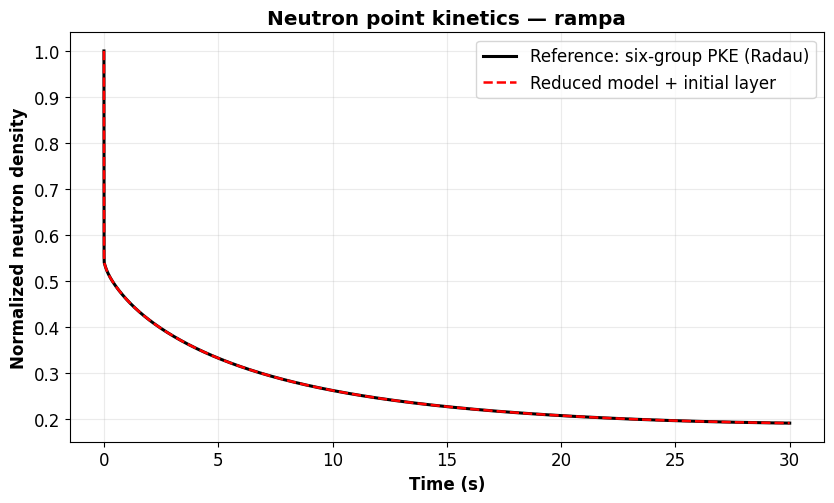

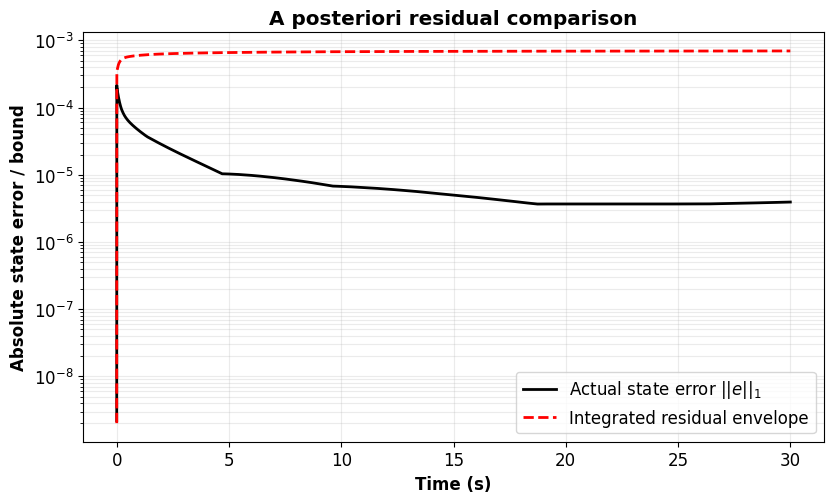

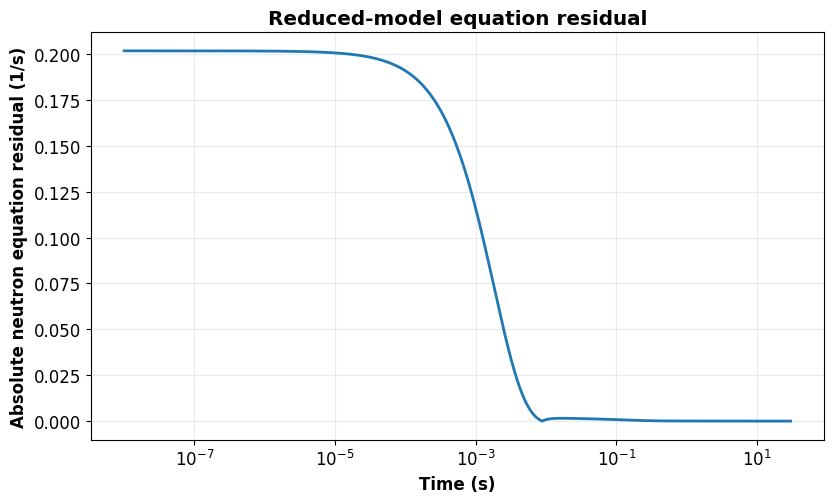

PNGs: /content/RCDPM_density.png /content/RCDPM_error_bound.png /content/RCDPM_residual.png


In [3]:
# -*- coding: utf-8 -*-
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, cumulative_trapezoid
from pathlib import Path

# Tabela 2 do manuscrito: os beta_i somam 0.00708 (na tabela beta_eff=0.00707).
beta_i = np.array([0.00021, 0.00111, 0.00111, 0.00324, 0.00106, 0.00035], float)
lam_i = np.array([0.01249, 0.03162, 0.11035, 0.32130, 1.34433, 8.94348], float)
Lambda = 2.37884e-5
beta = float(np.sum(beta_i))
B1 = float(np.dot(lam_i, beta_i))
B2 = float(np.dot(lam_i**2, beta_i))
n0 = 1.0
C0 = beta_i*n0/(Lambda*lam_i)

# Configuração de transiente estritamente subcrítico: rho(t) <= 0.
T_FINAL = 30.0
CASE = 'rampa'  # 'degrau', 'rampa', 'senoidal'
# Define rho, d rho/dt, d²rho/dt² e integral de D=beta-rho para a camada rápida.
def reactivity(t):
    t = np.asarray(t)
    if CASE == 'degrau':
        return -0.006 + 0*t, 0*t, 0*t, (beta+0.006)*t
    if CASE == 'rampa':
        r = 1.0e-4
        return -0.006+r*t, 0*t+r, 0*t, (beta+0.006)*t-r*t*t/2
    if CASE == 'senoidal':
        a, w = 0.001, 2*np.pi/10
        return -0.006+a*np.sin(w*t), a*w*np.cos(w*t), -a*w*w*np.sin(w*t), (beta+0.006)*t-a*(1-np.cos(w*t))/w
    raise ValueError('CASE inválido')

def algebraic(t, C):
    """Expressão algébrica corrigida n_a(C,t)."""
    rho, drho, _, _ = reactivity(t)
    D = beta-rho
    S = float(np.dot(lam_i,C))
    T = float(np.dot(lam_i**2,C))
    N = Lambda*S*D**2 + Lambda**2*T*D - Lambda**2*S*drho
    Q = D*(D**2+Lambda*B1)
    return N/Q

n_a0 = algebraic(0.0,C0)
z0 = n0 - n_a0

def initial_layer(t):
    _,_,_,int_D = reactivity(t)
    return z0*np.exp(-int_D/Lambda)

def approx_n(t,C):
    return algebraic(t,C)+initial_layer(t)

def approximate_rhs(t,C):
    n=approx_n(t,C)
    return beta_i/Lambda*n - lam_i*C

def full_rhs(t,y):
    n, C = y[0], y[1:]
    rho, _, _, _ = reactivity(t)
    return np.r_[((rho-beta)/Lambda)*n+np.dot(lam_i,C),beta_i/Lambda*n-lam_i*C]

def residual(t,C):
    """Resíduo da equação de n, com derivada analítica de n_a.
    As equações dos precursores são satisfeitas pelo modelo reduzido.
    """
    rho, drho, ddrho, _ = reactivity(t)
    D=beta-rho
    Dp=-drho
    S=float(np.dot(lam_i,C))
    T=float(np.dot(lam_i**2,C))
    U=float(np.dot(lam_i**3,C))
    n=approx_n(t,C)
    Sp=B1*n/Lambda-T
    Tp=B2*n/Lambda-U
    N=Lambda*S*D**2 + Lambda**2*T*D -Lambda**2*S*drho
    Q=D*(D**2+Lambda*B1)
    Np=Lambda*(Sp*D**2+2*S*D*Dp)+Lambda**2*(Tp*D+T*Dp)-Lambda**2*(Sp*drho+S*ddrho)
    Qp=Dp*(3*D**2+Lambda*B1)
    na_prime=(Np*Q-N*Qp)/Q**2
    z=initial_layer(t)
    nprime=na_prime-D/Lambda*z
    return nprime+D/Lambda*n-S

if np.any(np.asarray(reactivity(np.linspace(0,T_FINAL,501))[0])>0):
    print('ATENÇÃO: limite simples E<=int|R| requer rho<=0. Usando limite exponencial conservador.')

# Pontos densos perto do transiente prompt, e ao longo de 30 segundos.
tgrid = np.unique(np.r_[0., np.geomspace(1e-8,1e-1,1400),np.linspace(0,T_FINAL,1400)])
y0 = np.r_[n0,C0]
sol_full = solve_ivp(full_rhs,(0,T_FINAL),y0,method='Radau',rtol=2e-11,atol=2e-11,dense_output=True)
sol_red = solve_ivp(approximate_rhs,(0,T_FINAL),C0,method='BDF',rtol=2e-11,atol=2e-11,dense_output=True)
if not sol_full.success or not sol_red.success:
    raise RuntimeError(f'Falha no integrador: {sol_full.message}; {sol_red.message}')
full = sol_full.sol(tgrid)
C_red = sol_red.sol(tgrid)
n_red = np.array([approx_n(t,C) for t,C in zip(tgrid,C_red.T)])
R = np.array([residual(t,C) for t,C in zip(tgrid,C_red.T)])
err_n=np.abs(full[0]-n_red)
err_state=np.abs(full[0]-n_red)+np.sum(np.abs(full[1:]-C_red),axis=0)

# Prova do limite: A(t) é Metzler. Para rho<=0, as somas das colunas
# são (rho/Lambda,0,...,0), logo ||A||_1 logarithmic norm <= 0.
# Para rho>0, mu_1(A) = max(rho/Lambda,0) e aplicamos Gronwall.
rho_arr=np.asarray(reactivity(tgrid)[0])
mu=np.maximum(rho_arr/Lambda,0.)
# Integração do envelope escalar E'=mu E + abs(R), E(0)=0.
# Regra trapezoidal em forma de fator integrante; apenas aproximação numérica.
M=cumulative_trapezoid(mu,tgrid,initial=0.)
if np.max(M)>600:
    raise RuntimeError('Fator de amplificação muito grande; restrinja o transiente para este protótipo.')
E=np.exp(M)*cumulative_trapezoid(np.abs(R)*np.exp(-M),tgrid,initial=0.)
# E(t) é limite teórico (quando residual/integrais calculados exatamente);
# numericamente há incerteza da quadratura e dos solvers.

print('Caso:',CASE,'| beta (soma seis grupos):',f'{beta:.8f}','| Lambda:',Lambda)
print('n_alg(0+):',f'{n_a0:.8g}','| n_corr(0+):',f'{approx_n(0,C0):.8g}')
print('Erro abs. maximo em n:',f'{err_n.max():.6g}')
print('Erro abs. maximo da norma-1 do estado:',f'{err_state.max():.6g}')
print('Envelope integrado no final:',f'{E[-1]:.6g}')
print('Relação max ||erro||_1 / E (excluindo t=0):',f'{np.max(err_state[1:]/np.maximum(E[1:],1e-30)):.6g}')

out=Path('/content') if Path('/content').exists() else Path.cwd()
out.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size':12,'axes.labelweight':'bold','axes.titleweight':'bold'})
fig,ax=plt.subplots(figsize=(8.5,5.2))
ax.plot(tgrid,full[0],'k-',lw=2.2,label='Reference: six-group PKE (Radau)')
ax.plot(tgrid,n_red,'r--',lw=1.8,label='Reduced model + initial layer')
ax.set(xlabel='Time (s)',ylabel='Normalized neutron density',title=f'Neutron point kinetics — {CASE}')
ax.grid(alpha=.25);ax.legend();fig.tight_layout();fig.savefig(out/'RCDPM_density.png',dpi=300)

fig,ax=plt.subplots(figsize=(8.5,5.2))
ax.semilogy(tgrid[1:],np.maximum(err_state[1:],1e-18),'k',lw=2,label=r'Actual state error $||e||_1$')
ax.semilogy(tgrid[1:],np.maximum(E[1:],1e-18),'r--',lw=2,label='Integrated residual envelope')
ax.set(xlabel='Time (s)',ylabel='Absolute state error / bound',title='A posteriori residual comparison')
ax.grid(alpha=.25,which='both');ax.legend();fig.tight_layout();fig.savefig(out/'RCDPM_error_bound.png',dpi=300)

fig,ax=plt.subplots(figsize=(8.5,5.2))
ax.semilogx(tgrid[1:],np.abs(R[1:]),lw=2)
ax.set(xlabel='Time (s)',ylabel='Absolute neutron equation residual (1/s)',title='Reduced-model equation residual')
ax.grid(alpha=.25);fig.tight_layout();fig.savefig(out/'RCDPM_residual.png',dpi=300)
plt.show()
print('PNGs:',out/'RCDPM_density.png',out/'RCDPM_error_bound.png',out/'RCDPM_residual.png')
